# Dynamic Aperture
Thanks to SciBmad's support for both explicit Single Instruction, Multiple Data (SIMD) on the CPU and Single Instruction, Multiple Thread (SIMT) on the GPU, highly-parallelized and performant tracking simulations can be run on all types of architectures. Here we will do a dynamic aperture scan of the v6.3.1 Electron Storage Ring (ESR) of the Electron-Ion Collider (EIC) using SciBmad's `dynamic_aperture` function on an Apple Metal GPU. Also supported are NVIDIA CUDA, AMD ROCm, and Intel oneAPI GPUs.

Firstly, please be aware that SciBmad's `dynamic_aperture` function works differently than that in classical Bmad; in Bmad, the dynamic aperture is computed by tracking a particle initialized with some angle and radius in the x-y acceptance plane, and if it lives for the specified number of turns, then a larger radius is used. This is repeated until the particle is lost, and then that radius is specified as the dynamic aperture.

In SciBmad, a polar grid of particles spanning the entire acceptance plane, with density and maximums specifiable by the user, is pushed in parallel, all at once. At the end of tracking, particles will either be alive or lost - a binary heatmap is produced in the x-y acceptance plane. With this, the first lost radius along each angle is chosen as the dynamic aperture. We have found this approach to be significantly faster thanks to the (GPU-)parallelizability of it.

Apple Metal GPUs only support 32-bit floats, so we must specify `coordinates_number_type=np.float32` as a keyword argument.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scibmad as sb
gpu = sb.device("metal")  # installs the Julia package Metal.jl the first time

In [2]:
# Lattice in the SciBmad Github lattices directory
ring = sb.julia.include("../../lattices/esr-v6.3.1-tapered.jl").ring

In [3]:
# Turn on radiation
for ele in ring.line:
    ele.rad_damping = True

In [4]:
deltas = np.linspace(0, 1e-2, 11)
x_norm_da, y_norm_da = sb.dynamic_aperture(
    ring,
    n_turns=2000,
    emit_1=30e-9,
    emit_2=15e-9,
    emit_3=7.30474E-06,
    n_r=30,
    n_theta=65,
    max_sig_x=15,
    max_sig_y=22,
    deltas=deltas,
    backend=gpu.module.MetalBackend(),  # Specify a Metal backend
    coordinates_number_type=np.float32,  # Metal only compatible with Float32
)

Initializing dynamic_aperture with 20746 particles
Initializing bunch on GPU
Finished turn 2000 out of 2000
Tracking complete


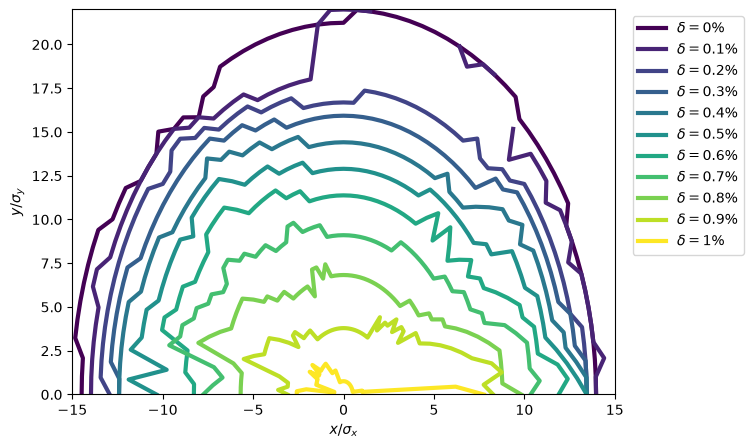

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
colors = plt.cm.viridis(np.linspace(0, 1, len(deltas)))
for i in range(len(deltas)):
    ax.plot(x_norm_da[:, i], y_norm_da[:, i], linewidth=3, color=colors[i],
            label=rf"$\delta={deltas[i]*100:.1g}\%$")
ax.set(xlabel=r"$x/\sigma_x$", ylabel=r"$y/\sigma_y$", xlim=(-15, 15), ylim=(0, 22))
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1));